# Lab 2.3 — Evaluar la recuperación de un RAG

**Curso:** AWS Certified Machine Learning Engineer – Associate (MLA-C02) · **Tema:** 2.3 (enlaza con 4.3)

Reproduce localmente lo que hacen Amazon Bedrock Knowledge Bases y las evaluaciones RAG de Amazon Bedrock:

1. Dividir un corpus en chunks con dos estrategias.
2. Medir la recuperación con **Recall@k**, **Precision@k** y **MRR**, sin generar respuestas.
3. Ver cómo, sin **filtro de metadatos**, una pregunta recupera datos de otro tenant.
4. Separar los fallos de recuperación de los fallos de generación.

No requiere cuenta de AWS, credenciales ni modelos externos: TF-IDF sustituye a los embeddings y un generador extractivo, al LLM.

## 0. Preparación

Los módulos reutilizables están en `src/`.

In [1]:
import sys

sys.path.insert(0, "src")

In [2]:
from pathlib import Path

import pandas as pd

import chunking
import corpus
import evaluation
import plots
from retrieval import Retriever

LANG = "es"
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 70)

## 1. Corpus y preguntas etiquetadas

Dos empresas (*tenants*), `andina` y `boreal`, comparten la misma plataforma. Cada una tiene 6 políticas internas con la **misma estructura y distintos valores**: es el caso típico de un SaaS multi-tenant.

Cada pregunta tiene una respuesta esperada y su **frase de evidencia** en el documento del tenant correcto. Las preguntas no mencionan la empresa, igual que un usuario real.

In [3]:
docs = corpus.documents(LANG)
queries = corpus.queries(LANG)
corpus.export(docs, Path("data/corpus"))
print(f"documents={len(docs)}  tenants={sorted({d['tenant'] for d in docs})}  questions={len(queries)}\n")
print(docs[0]["doc_id"])
print(docs[0]["text"])

documents=12  tenants=['andina', 'boreal']  questions=30

andina/vacaciones
En Andina Foods, cada persona con contrato indefinido tiene 22 días hábiles de vacaciones pagadas por año calendario. Los días se acumulan de forma proporcional desde el primer mes de trabajo y se registran en el portal de recursos humanos.

Las vacaciones se solicitan en el portal con al menos 15 días de anticipación. La persona responsable del equipo aprueba o rechaza la solicitud en un plazo de tres días hábiles. Los cierres contables de fin de mes pueden tener restricciones.

Al terminar el año se pueden trasladar como máximo 5 días no usados al año siguiente. Los días trasladados vencen el 31 de marzo. Los días no utilizados no se pagan en efectivo, salvo cuando la ley lo exige al finalizar el contrato.


In [4]:
pd.DataFrame(queries)[["query_id", "tenant", "question", "answer", "doc_id"]].head(6)

,query_id,tenant,question,answer,doc_id
0,andina-q01,andina,¿Cuántos días de vacaciones pagadas tengo al año?,22 días hábiles,andina/vacaciones
1,boreal-q01,boreal,¿Cuántos días de vacaciones pagadas tengo al año?,18 días hábiles,boreal/vacaciones
2,andina-q02,andina,¿Con cuánta anticipación debo pedir mis vacaciones?,15 días de anticipación,andina/vacaciones
3,boreal-q02,boreal,¿Con cuánta anticipación debo pedir mis vacaciones?,30 días de anticipación,boreal/vacaciones
4,andina-q03,andina,¿Cuántos días libres que no tomé puedo pasar al próximo año?,5 días no usados,andina/vacaciones
5,boreal-q03,boreal,¿Cuántos días libres que no tomé puedo pasar al próximo año?,10 días no usados,boreal/vacaciones


`export` guarda cada documento con un archivo `.metadata.json`, el formato que usa un origen de datos S3 de Bedrock Knowledge Bases para los atributos de filtrado:

In [5]:
print(Path(f"data/corpus/{docs[0]['doc_id']}.txt.metadata.json").read_text())

{
  "metadataAttributes": {
    "tenant": "andina",
    "topic": "vacaciones"
  }
}


## 2. Dos estrategias de chunking

- **`fixed-30`**: ventanas de 30 palabras sin solapamiento. Corta frases y párrafos.
- **`paragraph`**: un chunk por párrafo. Respeta los límites lógicos del documento.

Un chunk es **relevante** si se solapa con la frase de evidencia del documento correcto.

In [6]:
chunks = {name: chunking.chunk_corpus(docs, name) for name in chunking.STRATEGIES}
for name, cs in chunks.items():
    words = pd.Series([len(c["text"].split()) for c in cs])
    print(f"{name:<10} chunks={len(cs):>3}  words/chunk: mean={words.mean():.0f}  min={words.min()}  max={words.max()}")

fixed-30   chunks= 50  words/chunk: mean=24  min=4  max=30
paragraph  chunks= 36  words/chunk: mean=34  min=30  max=43


In [7]:
# Una pregunta cuya evidencia queda partida en dos chunks fijos. A question whose evidence is split across two fixed chunks.
q = next(q for q in queries if len(evaluation.relevant_ids(q, chunks["fixed-30"])) > 1)
print(q["query_id"], "|", q["answer"])
for name, cs in chunks.items():
    print(f"\n--- {name}")
    for c in cs:
        if c["chunk_id"] in evaluation.relevant_ids(q, cs):
            print(f"[{c['chunk_id']}] {c['text']!r}")

andina-q03 | 5 días no usados

--- fixed-30
[andina/vacaciones#fixed-2] 'o rechaza la solicitud en un plazo de tres días hábiles. Los cierres contables de fin de mes pueden tener restricciones.\n\nAl terminar el año se pueden trasladar como máximo'
[andina/vacaciones#fixed-3] '5 días no usados al año siguiente. Los días trasladados vencen el 31 de marzo. Los días no utilizados no se pagan en efectivo, salvo cuando la ley lo exige'

--- paragraph
[andina/vacaciones#paragraph-2] 'Al terminar el año se pueden trasladar como máximo 5 días no usados al año siguiente. Los días trasladados vencen el 31 de marzo. Los días no utilizados no se pagan en efectivo, salvo cuando la ley lo exige al finalizar el contrato.'


Con `fixed-30`, la frase de evidencia queda repartida en dos chunks: ninguno la contiene completa.

## 3. Evaluar solo la recuperación

Sin generar respuestas, para cada pregunta y cada k:

- **Recall@k**: fracción de los chunks relevantes que aparece en el top-k.
- **Precision@k**: fracción del top-k que es relevante.
- **MRR**: media de 1/posición del primer chunk relevante.
- **Fuga**: el top-k contiene un chunk de otro tenant.

Cada estrategia se evalúa sin filtro y con el filtro `tenant = <tenant de la pregunta>`.

In [8]:
retrievers = {name: Retriever(cs, LANG) for name, cs in chunks.items()}
summaries = {
    (name, use_filter): evaluation.summary(evaluation.retrieval_metrics(r, queries, use_filter=use_filter))
    for name, r in retrievers.items()
    for use_filter in (False, True)
}
pd.concat({f"{name} | filter={use_filter}": s.loc[[1, 3, 5]] for (name, use_filter), s in summaries.items()})

recall  precision  coverage    mrr  leak
                         k                                          
fixed-30 | filter=False  1   0.400      0.433     0.411  0.433   0.5
                         3   0.800      0.289     0.811  0.633   1.0
                         5   0.900      0.200     0.893  0.655   1.0
fixed-30 | filter=True   1   0.783      0.833     0.809  0.833   0.0
                         3   0.967      0.356     0.960  0.894   0.0
                         5   1.000      0.227     0.999  0.894   0.0
paragraph | filter=False 1   0.433      0.433     0.433  0.433   0.5
                         3   0.900      0.300     0.900  0.661   1.0
                         5   0.967      0.193     0.967  0.676   1.0
paragraph | filter=True  1   0.867      0.867     0.867  0.867   0.0
                         3   0.967      0.322     0.967  0.911   0.0
                         5   1.000      0.200     1.000  0.919   0.0

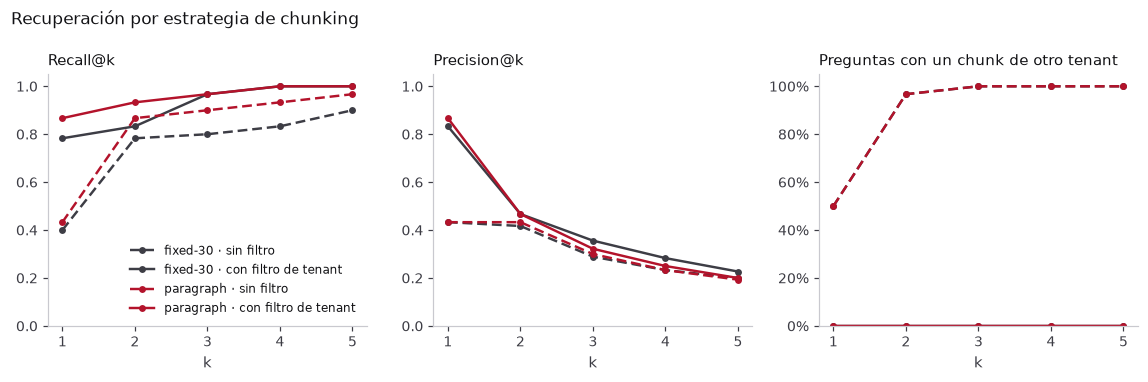

In [9]:
plots.metrics_vs_k(summaries, LANG);

- **Sin filtro**, la mitad de los top-1 son del otro tenant: los dos documentos son casi idénticos y solo cambian los valores. Recall@1 no pasa de 0,43.
- **Con filtro**, `paragraph` gana en Recall@1 porque la evidencia queda entera en un chunk.
- Precision@k favorece a `fixed-30` en k ≥ 2 solo porque la evidencia partida cuenta como **dos** chunks relevantes. Para comparar estrategias de chunking, usa recall o cobertura, no solo precisión.

## 4. Filtro de metadatos por tenant (enlaza con el tema 4.3)

La misma pregunta, con y sin filtro. Los chunks de ambos tenants empatan en puntuación, así que el orden entre ellos es arbitrario. Sin filtro, el del otro tenant aparece primero: la respuesta sería **plausible y falsa**, y además expone datos ajenos.

In [10]:
r = retrievers["paragraph"]
q = next(q for q in queries if r.search(q["question"], k=1)[0]["tenant"] != q["tenant"])
print(f"{q['query_id']} | tenant={q['tenant']} | expected: {q['answer']}\n{q['question']}")
for use_filter in (False, True):
    print(f"\nfilter={use_filter}")
    for h in r.search(q["question"], k=3, tenant=q["tenant"] if use_filter else None):
        print(f"  {h['score']:.3f}  {h['chunk_id']:<26} {h['text'][:60]}...")

boreal-q01 | tenant=boreal | expected: 18 días hábiles
¿Cuántos días de vacaciones pagadas tengo al año?

filter=False
  0.391  andina/vacaciones#paragraph-0 En Andina Foods, cada persona con contrato indefinido tiene ...
  0.391  boreal/vacaciones#paragraph-0 En Boreal Health, cada persona con contrato indefinido tiene...
  0.224  andina/vacaciones#paragraph-2 Al terminar el año se pueden trasladar como máximo 5 días no...

filter=True
  0.391  boreal/vacaciones#paragraph-0 En Boreal Health, cada persona con contrato indefinido tiene...
  0.220  boreal/vacaciones#paragraph-2 Al terminar el año se pueden trasladar como máximo 10 días n...
  0.157  boreal/vacaciones#paragraph-1 Las vacaciones se solicitan en el portal con al menos 30 día...


En Bedrock Knowledge Bases, el equivalente es un filtro `equals` en `Retrieve` o `RetrieveAndGenerate`:

```json
"retrievalConfiguration": {
  "vectorSearchConfiguration": {
    "numberOfResults": 3,
    "filter": { "equals": { "key": "tenant", "value": "boreal" } }
  }
}
```

El valor del filtro debe salir de la identidad autenticada de la aplicación, nunca del texto que escribe el usuario.

## 5. Separar recuperación y generación

Un generador extractivo de juguete (sustituye al LLM) responde con la frase del top-3 que comparte más palabras con la pregunta. Cada respuesta se clasifica:

- **Correcta**: contiene la respuesta esperada.
- **Dato de otro tenant**: la frase elegida viene de otro tenant.
- **Fallo de recuperación**: la evidencia no estaba en el top-3.
- **Fallo de generación**: la evidencia estaba en el top-3, pero la respuesta es incorrecta.

In [11]:
results = {
    f"{name} | filter={use_filter}": evaluation.end_to_end(r, queries, k=3, use_filter=use_filter, lang=LANG)
    for name, r in retrievers.items()
    for use_filter in (False, True)
}
pd.DataFrame({name: res["outcome"].value_counts() for name, res in results.items()}).fillna(0).astype(int).T

outcome,correct,generation_miss,retrieval_miss,wrong_tenant
fixed-30 | filter=False,12,1,2,15
fixed-30 | filter=True,24,6,0,0
paragraph | filter=False,12,2,1,15
paragraph | filter=True,24,5,1,0


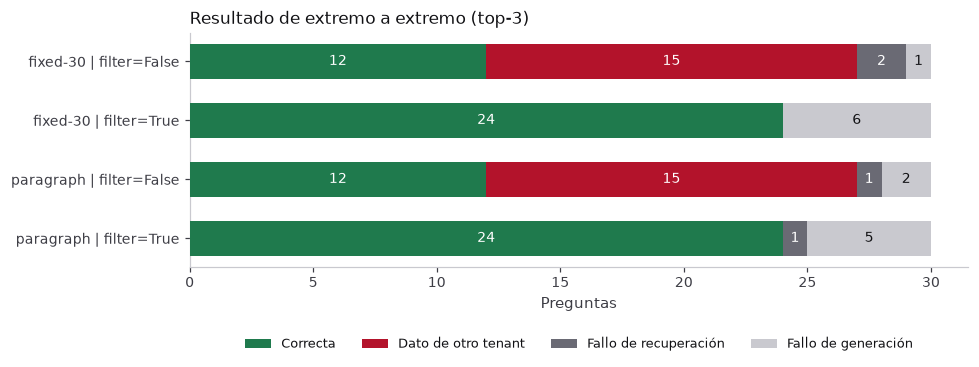

In [12]:
plots.outcomes(results, LANG);

In [13]:
res = results["paragraph | filter=False"]
res[res["outcome"] == "wrong_tenant"][["query_id", "expected", "generated"]].head(3)

,query_id,expected,generated
1,boreal-q01,18 días hábiles,"En Andina Foods, cada persona con contrato indefinido tiene 22 día..."
3,boreal-q02,30 días de anticipación,Las vacaciones se solicitan en el portal con al menos 15 días de a...
5,boreal-q03,10 días no usados,Al terminar el año se pueden trasladar como máximo 5 días no usado...


In [14]:
res = results["paragraph | filter=True"]
res[res["outcome"] != "correct"][["query_id", "expected", "generated", "retrieved_evidence"]]

,query_id,expected,generated,retrieved_evidence
6,andina-q04,40 USD por día,"En Andina Foods, los gastos de viaje de trabajo se reembolsan con ...",True
7,boreal-q04,55 USD por día,"En Boreal Health, los gastos de viaje de trabajo se reembolsan con...",True
12,andina-q07,14 caracteres,La persona de guardia recibe las alertas en el teléfono y debe ten...,True
13,boreal-q07,16 caracteres,La persona de guardia recibe las alertas en el teléfono y debe ten...,True
14,andina-q08,5 minutos de inactividad,La persona de guardia recibe las alertas en el teléfono y debe ten...,True
15,boreal-q08,10 minutos de inactividad,Después de cada incidente de severidad 1 se redacta un análisis po...,False


La exactitud de extremo a extremo, por sí sola, no dice qué arreglar:

- **Sin filtro**, la mitad de las respuestas usa datos del otro tenant. Es un problema de **recuperación y de seguridad**: cambiar el modelo o el prompt no lo resuelve.
- **Con filtro**, el Recall@3 es alto, pero algunas respuestas siguen fallando con la evidencia en el contexto (`retrieved_evidence=True`). Ahí hay que mejorar la **generación** (prompt o modelo), no el chunking.

## 6. Equivalencia en AWS

| Este laboratorio | En AWS | Diferencias principales |
|---|---|---|
| `chunking.py` | Chunking de Bedrock Knowledge Bases: predeterminado (~300 tokens), tamaño fijo con solapamiento, jerárquico, semántico o sin chunking | Bedrock cuenta tokens, no palabras, y el chunking semántico usa un modelo fundacional con costo adicional. |
| `retrieval.py` (TF-IDF) | Modelo de embeddings + vector store; búsqueda semántica o híbrida | Los embeddings capturan sinónimos que TF-IDF no ve. |
| `Retriever.search(tenant=...)` | Filtro de metadatos `equals` en `Retrieve` / `RetrieveAndGenerate`, con atributos de `.metadata.json` | Bedrock admite más operadores (`in`, `greaterThan`, `andAll`, `orAll`…). |
| `evaluation.retrieval_metrics` | Evaluación RAG de Bedrock, tipo *Retrieve only*: *context relevance* y *context coverage* | Bedrock usa un LLM como juez y no necesita IDs de chunks; *context coverage* requiere ground truth. Aquí las métricas son deterministas. |
| `evaluation.end_to_end` | Evaluación RAG de Bedrock, tipo *Retrieve and generate*: *correctness*, *faithfulness*, *citation precision*… | Bedrock también puede evaluar un RAG externo si le das sus respuestas. |

### Prueba esto

- Antes de la sección 2, añade `chunking.STRATEGIES["fixed-30-ov10"] = lambda d: chunking.fixed(d, 30, overlap=10)` y compara Recall@1.
- Quita el filtro solo para un tenant y mide cuántas respuestas filtran datos.
- Reformula una pregunta con sinónimos y mira cómo cae el recall con TF-IDF.